# 5. Experimentação

**CatBoost aplicado à previsão de churn**

Atividade Final de Aprendizado de Máquina I · FATEC Jundiaí · Ciência de Dados

| Aluna | Professor | Tema |
|:--|:--|:--|
| Mariana Costa de Mello | Mateus Guilherme Fuini | CatBoost |

| # | Pergunta | O que varia |
|:--|:--|:--|
| E1 | O tratamento nativo das categóricas faz diferença? | Nativo, one-hot, ordinal, one-hot interno |
| E2 | Como profundidade e taxa de aprendizado interagem? | `depth` x `learning_rate` |
| E3 | Regularização e Ordered Boosting ajudam? | `l2_leaf_reg` x `boosting_type` |
| E4 | Como lidar com o desbalanceamento? | `auto_class_weights` |
| E5 | O Ordered TS evita vazamento? | Coluna de ruído com muitas categorias |

## Preparação

A mesma preparação é usada em todos os notebooks:

- `TotalCharges` vem como texto e os 11 valores em branco são de clientes com 0 meses de casa, então viram 0
- `customerID` sai porque é só um identificador
- Divisão estratificada em 60% treino, 20% validação e 20% teste, com semente 42

A primeira célula instala as bibliotecas; o `%%capture` esconde as mensagens da instalação.

In [1]:
%%capture
%pip install catboost shap category_encoders

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.precision", 3)
SEED = 42

df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].eq("Yes").astype(int)
cats = X.select_dtypes(exclude="number").columns.tolist()

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

## Funções de apoio

- `rodar_cv`: validação cruzada estratificada de 5 folds no treino + validação com `cross_validate`, que já devolve as métricas de cada fold, a AUC no treino e o tempo. Usada no E1, E4 e E5
- `treinar`: treina no treino com early stopping na validação. Usada no E2 e E3, porque o número de árvores muda com os parâmetros

In [3]:
import time
from itertools import product

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
base = dict(iterations=600, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0)
metricas = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "Precisão": "precision", "Recall": "recall", "F1": "f1", "LogLoss": "neg_log_loss"}

def rodar_cv(modelo, dados=X_trval, coluna=None, **fit):
    r = cross_validate(modelo, dados, y_trval, cv=cv, scoring=metricas, params=fit, return_train_score=True, return_estimator=bool(coluna))
    res = {nome: abs(r[f"test_{nome}"].mean()) for nome in metricas}
    res |= {"dp AUC": r["test_ROC-AUC"].std(), "AUC treino": r["train_ROC-AUC"].mean(), "Tempo (s)": r["fit_time"].mean()}
    if coluna:
        cb = [e[-1] if hasattr(e, "steps") else e for e in r["estimator"]]
        res["Importância (%)"] = np.mean([dict(zip(m.feature_names_, m.get_feature_importance()))[coluna] for m in cb])
    return res

def treinar(**params):
    inicio = time.time()
    m = CatBoostClassifier(iterations=3000, eval_metric="AUC", early_stopping_rounds=200, random_seed=SEED, verbose=0, cat_features=cats, **params)
    m.fit(X_train, y_train, eval_set=(X_val, y_val))
    return {**params, "AUC val": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]),
            "AUC treino": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]), "Árvores": m.tree_count_, "Tempo (s)": time.time() - inicio}

def tabela(dic):
    return pd.DataFrame(dic).T.style.format("{:.3f}").highlight_max(subset=["ROC-AUC", "PR-AUC", "F1"], color="#d4e6f1")

## E1. Tratamento das categóricas

O mesmo CatBoost recebendo as categóricas de quatro jeitos. One-hot e ordinal usam encoders do scikit-learn dentro de um pipeline. O one-hot interno força o CatBoost a não usar Ordered TS (`one_hot_max_size=255`), o que isola o efeito dele.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

onehot = make_column_transformer((OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats), remainder="passthrough")
ordinal = make_column_transformer((OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cats), remainder="passthrough")

e1 = {
    "Nativo (Ordered TS)": rodar_cv(CatBoostClassifier(**base), cat_features=cats),
    "One-hot": rodar_cv(make_pipeline(onehot, CatBoostClassifier(**base))),
    "Ordinal": rodar_cv(make_pipeline(ordinal, CatBoostClassifier(**base))),
    "One-hot interno": rodar_cv(CatBoostClassifier(**base, one_hot_max_size=255), cat_features=cats),
}
tabela(e1)

,ROC-AUC,PR-AUC,Precisão,Recall,F1,LogLoss,dp AUC,AUC treino,Tempo (s)
Nativo (Ordered TS),0.842,0.654,0.661,0.504,0.572,0.423,0.009,0.915,8.478
One-hot,0.835,0.643,0.639,0.505,0.564,0.436,0.010,0.969,2.180
Ordinal,0.834,0.646,0.645,0.499,0.562,0.437,0.006,0.969,1.462
One-hot interno,0.835,0.641,0.630,0.499,0.557,0.436,0.006,0.969,1.503


> **O modo nativo foi o melhor em todas as métricas**, com AUC de 0,842 contra 0,834 a 0,835 das outras formas.

- A diferença de AUC é pequena (~0,007), mas o maior ganho está no **overfitting**: a AUC no treino cai de 0,969 para 0,915
- O one-hot interno ficou igual às codificações externas, então o ganho vem do Ordered TS e das combinações de categóricas
- Custo: o nativo levou de 4 a 6 vezes mais tempo por fold

## E2. Profundidade x taxa de aprendizado

Grade 4 x 4 com early stopping. `product` gera as 16 combinações.

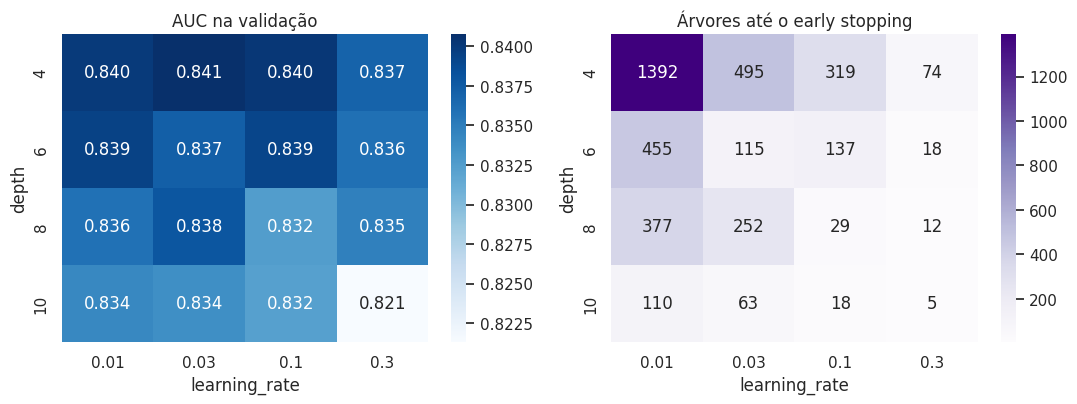

In [5]:
e2 = pd.DataFrame([treinar(depth=d, learning_rate=lr) for d, lr in product([4, 6, 8, 10], [0.01, 0.03, 0.1, 0.3])])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(e2.pivot(index="depth", columns="learning_rate", values="AUC val"), annot=True, fmt=".3f", cmap="Blues", ax=axes[0]).set_title("AUC na validação")
sns.heatmap(e2.pivot(index="depth", columns="learning_rate", values="Árvores"), annot=True, fmt=".0f", cmap="Purples", ax=axes[1]).set_title("Árvores até o early stopping")
plt.show()

> **Melhor combinação: `depth=4` e `learning_rate=0.03`** (AUC 0,841 com 495 árvores).

- Árvores profundas (8 e 10) e taxa alta (0,3) pioram o resultado
- Entre as combinações razoáveis a diferença fica abaixo de 0,005, então o CatBoost é pouco sensível aos parâmetros
- Com taxa menor, o early stopping deixa mais árvores

## E3. Regularização e tipo de boosting

Com `depth=6` e `learning_rate=0.03`, variando `l2_leaf_reg` e comparando `Plain` com `Ordered`. O gap é a diferença entre AUC no treino e na validação.

In [6]:
e3 = pd.DataFrame([treinar(depth=6, learning_rate=0.03, boosting_type=bt, l2_leaf_reg=l2) for bt, l2 in product(["Plain", "Ordered"], [1, 3, 10, 30, 100])])
e3["Gap"] = e3["AUC treino"] - e3["AUC val"]
e3.drop(columns=["depth", "learning_rate"]).style.format(precision=3).hide()

boosting_type,l2_leaf_reg,AUC val,AUC treino,Árvores,Tempo (s),Gap
Plain,1,0.838,0.874,198,5.402,0.035
Plain,3,0.837,0.867,115,4.234,0.030
Plain,10,0.838,0.868,117,3.618,0.029
Plain,30,0.839,0.868,233,5.633,0.029
Plain,100,0.839,0.865,219,5.055,0.026
Ordered,1,0.840,0.861,274,10.738,0.021
Ordered,3,0.840,0.861,254,10.383,0.022
Ordered,10,0.840,0.883,821,27.274,0.043
Ordered,30,0.839,0.865,374,13.596,0.026
Ordered,100,0.838,0.869,494,17.242,0.031


> **Efeito pequeno nesta base.** A AUC fica entre 0,837 e 0,840 em todos os casos.

- Mais `l2_leaf_reg` diminui o gap entre treino e validação (0,035 para 0,026 no Plain)
- O Ordered teve o menor gap (0,021) e AUC um pouco maior, mas foi de 2 a 7 vezes mais lento
- Decisão: manter o padrão (`Plain`, `l2_leaf_reg=3`)

## E4. Desbalanceamento

Só 26,5% dos clientes cancelam. `Balanced` dá peso inversamente proporcional à frequência de cada classe e `SqrtBalanced` usa a raiz desse peso. Precisão, recall e F1 usam o limiar de 0,5.

In [7]:
e4 = {nome: rodar_cv(CatBoostClassifier(**base, auto_class_weights=peso), cat_features=cats)
      for nome, peso in [("Sem pesos", None), ("SqrtBalanced", "SqrtBalanced"), ("Balanced", "Balanced")]}
pd.DataFrame(e4).T[["ROC-AUC", "PR-AUC", "Precisão", "Recall", "F1", "LogLoss"]].style.format("{:.3f}")

,ROC-AUC,PR-AUC,Precisão,Recall,F1,LogLoss
Sem pesos,0.842,0.654,0.661,0.504,0.572,0.423
SqrtBalanced,0.841,0.657,0.597,0.645,0.620,0.436
Balanced,0.841,0.655,0.544,0.759,0.633,0.474


> **Os pesos não mudam a ROC-AUC**, só onde fica o corte.

- `Balanced` sobe o recall de 0,50 para 0,76, mas a precisão cai de 0,66 para 0,54
- A log-loss piora (0,423 para 0,474) porque as probabilidades ficam infladas
- Decisão: sem pesos, ajustando o limiar no Notebook 6, que tem o mesmo efeito sem distorcer as probabilidades

## E5. Alta cardinalidade e vazamento

Uma coluna `codigo_ruido` com códigos aleatórios (cerca de 1.870 valores, 3 clientes por código) é adicionada à base. Ela **não tem relação nenhuma** com o churn, então um bom método deveria ignorá-la. Quatro cenários:

| Cenário | Como a coluna entra |
|:--|:--|
| Sem a coluna | Referência |
| Nativo | Categórica no CatBoost (Ordered TS) |
| Target encoding simples | `TargetEncoder` do `category_encoders`, média do alvo incluindo a própria linha |
| Target encoding com cross-fitting | `TargetEncoder` do scikit-learn, que codifica cada linha com médias de outras partes |

In [17]:
from category_encoders import TargetEncoder as TargetEncoderSimples
from sklearn.preprocessing import TargetEncoder

X5 = X_trval.assign(codigo_ruido=np.random.default_rng(SEED).integers(0, 2000, len(X_trval)).astype(str))

def com_encoder(encoder):
    colunas = make_column_transformer((encoder, ["codigo_ruido"]), remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
    return make_pipeline(colunas, CatBoostClassifier(**base))

e5 = {
    "Sem a coluna": rodar_cv(CatBoostClassifier(**base), cat_features=cats),
    "Nativo": rodar_cv(CatBoostClassifier(**base), X5, "codigo_ruido", cat_features=cats + ["codigo_ruido"]),
    "Target encoding simples": rodar_cv(com_encoder(TargetEncoderSimples(min_samples_leaf=1, smoothing=1)), X5, "codigo_ruido", catboostclassifier__cat_features=cats),
    "Target encoding com cross-fitting": rodar_cv(com_encoder(TargetEncoder(random_state=SEED)), X5, "codigo_ruido", catboostclassifier__cat_features=cats),
}
pd.DataFrame(e5).T[["AUC treino", "ROC-AUC", "Importância (%)"]].style.format("{:.3f}", na_rep="")

,AUC treino,ROC-AUC,Importância (%)
Sem a coluna,0.915,0.842,
Nativo,0.894,0.843,9.968
Target encoding simples,0.983,0.658,43.964
Target encoding com cross-fitting,0.906,0.840,6.392


> **Com target encoding simples, a coluna de ruído derrubou a AUC de 0,84 para 0,66.** Com o Ordered TS, nada mudou.

- No encoding simples, a coluna virou a mais importante do modelo (44%) e a AUC no treino foi a 0,98. Como cada código tem ~3 clientes, a média já carrega o alvo da própria linha
- No modo nativo a AUC ficou em 0,843, igual à base sem a coluna
- O `TargetEncoder` do scikit-learn, com cross-fitting, também evita o problema. A regra é a mesma: não codificar uma linha usando o alvo dela

## Resumo dos experimentos

| # | Resultado |
|:--|:--|
| E1 | Nativo foi o melhor e reduziu o overfitting, com custo de tempo |
| E2 | `depth=4` e `learning_rate=0.03`; pouca sensibilidade a parâmetros |
| E3 | Regularização e Ordered Boosting com efeito pequeno; mantido o padrão |
| E4 | Pesos trocam precisão por recall e pioram a calibração; melhor ajustar o limiar |
| E5 | O Ordered TS evitou o vazamento que derrubou a AUC para 0,66 |